In [1]:
import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import scanpy as sc
import pertpy as pt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [25]:
def run_sccoda_analysis(whole_adata, fractions, seeds, output_dir="data"):
    """
    Runs the sccoda analysis for each combination of fraction and seed.
    Saves the effect DataFrames to the specified output directory.
    """
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    for seed in seeds:
        for fraction in fractions:
            fraction_str = str(fraction).replace(".", "_")
            filename = f"{output_dir}/effect_df_{fraction_str}_seed_{seed}.pkl"
            
            # Skip if the file already exists to avoid redundant computations
            if os.path.exists(filename):
                print(f"File already exists: {filename}, skipping computation.")
                continue
            
            print(f"Running sccoda for Fraction: {fraction}, Seed: {seed}")
            # Subsample adata with Scanpy
            adata = sc.pp.subsample(whole_adata, fraction=fraction, copy=True, random_state=seed)
            
            # Initialize the sccoda model
            sccoda_model = pt.tl.Sccoda()
            sccoda_data = sccoda_model.load(
                adata,
                type="cell_level",
                generate_sample_level=True,
                cell_type_identifier="cell_type",
                sample_identifier="cytokine",
            )
            
            # Prepare the data
            sccoda_data = sccoda_model.prepare(
                sccoda_data,
                modality_key="coda",
                formula="C(cytokine, Treatment('PBS'))",
            )
            
            # Run the NUTS sampler
            sccoda_model.run_nuts(sccoda_data, modality_key="coda", num_warmup=200, num_samples=5000)
            
            # Set the False Discovery Rate (FDR)
            sccoda_model.set_fdr(sccoda_data, modality_key="coda", est_fdr=0.4)
            
            # Save the effect DataFrame
            sccoda_model.get_effect_df(sccoda_data).to_pickle(filename)
            
            # Print the mean of credible effects
            mean_effect = sccoda_model.credible_effects(sccoda_data).mean()
            print(f"Fraction {fraction}, Seed {seed}: Mean Credible Effect = {mean_effect}")

def collect_non_zero_means(fractions, seeds, data_dir="data"):
    """
    Collects the fraction of non-zero effects for each fraction and seed.
    Returns a dictionary with fractions as keys and lists of non-zero means as values.
    """
    non_zero_means_dict = {}  # Key: fraction, Value: list of non_zero_mean across seeds
    
    for fraction in fractions:
        non_zero_means = []
        fraction_str = str(fraction).replace(".", "_")
        for seed in seeds:
            # Construct the filename
            filename = f"{data_dir}/effect_df_{fraction_str}_seed_{seed}.pkl"
            # Check if the file exists to avoid errors
            if os.path.exists(filename):
                # Load effect_df for this fraction and seed
                effect_df = pd.read_pickle(filename)
                # Calculate the fraction of non-zero effects
                non_zero_mean = effect_df['Final Parameter'].abs().gt(0).mean()
                non_zero_means.append(non_zero_mean)
                print(f"Collected Non-zero Effect for Fraction: {fraction}, Seed: {seed} = {non_zero_mean}")
            else:
                print(f"File not found: {filename}, skipping.")
                continue
        # Store the list of non_zero_means for this fraction
        non_zero_means_dict[fraction] = non_zero_means
    
    return non_zero_means_dict

def plot_results(non_zero_means_dict, fractions, output_dir="figures"):
    """
    Plots the boxplot and line plot with shaded standard deviation
    of the fraction of significant changes in cell abundance per cell type.
    """
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    # Prepare data for plotting
    data_to_plot = [non_zero_means_dict[fraction] for fraction in fractions]
    
    # Calculate medians for the boxplot
    medians = [np.median(non_zero_means_dict[fraction]) for fraction in fractions]
    
    # Plotting the boxplot with median line
    plt.figure(figsize=(10, 6))
    box = plt.boxplot(data_to_plot, labels=fractions, patch_artist=True)
    
    # Customize box colors
    colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(fractions)))
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
    
    # Plot a line connecting the medians
    plt.plot(range(1, len(fractions) + 1), medians, color='red', marker='o', linestyle='-', linewidth=2, label='Median')
    
    # Add labels, title, and legend
    plt.xlabel('Dataset Fraction')
    plt.ylabel('Fraction of Significant Changes in Cell Abundance per Cell Type')
    plt.title('Significant Cell Abundance Changes Across 5 Seeds')
    plt.ylim(0, 1)
    plt.grid(True, axis='y')
    plt.legend()
    
    # Save the boxplot
    boxplot_filename = f"{output_dir}/fraction_vs_non_zero_effect_boxplot_with_medians.png"
    plt.savefig(boxplot_filename)
    print(f"Boxplot saved to {boxplot_filename}")
    plt.show()

def plot_clustermaps(output_dir="figures"):
    """
    Plots clustermaps for the effect DataFrames of the whole dataset, using a symmetric colormap range across the two plots.
    """
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    fractions_to_plot = [1.0]
    dataframes = {}
    all_values = []
    
    # Load dataframes and collect all values to find global min and max
    for fraction in fractions_to_plot:
        fraction_str = str(fraction).replace(".", "_")
        filename = f"data/effect_df_{fraction_str}_seed_0.pkl"
        
        if os.path.exists(filename):
            df = pd.read_pickle(filename)
            df.reset_index(inplace=True)
            df['Covariate'] = df['Covariate'].str.replace(r'.*\)T\.', '', regex=True)
            df_pivot = df.pivot(index='Covariate', columns='Cell Type', values='Final Parameter')
            dataframes[fraction] = df_pivot
            all_values.extend(df_pivot.values.flatten())
        else:
            print(f"Effect DataFrame not found for fraction {fraction}, file {filename} missing.")
            continue
    
    if not dataframes:
        print("No dataframes to plot.")
        return
    
    # Set symmetric colormap range
    abs_max = abs(max(global_min := np.min(all_values), global_max := np.max(all_values)))
    print(f"Global min: {global_min}, Global max: {global_max}, Symmetric range: -{abs_max} to {abs_max}")
    
    # Plot clustermap for fraction 1.0
    fraction = 1.0
    df_pivot = dataframes[fraction]
    fraction_str = str(fraction).replace(".", "_")
    
    plt.figure()
    clustermap = sns.clustermap(
        df_pivot,
        method='average',
        metric='euclidean',
        cmap='vlag',
        figsize=(12, 18),
        dendrogram_ratio=(0.2, 0.2),
        cbar_pos=(0.02, 0.8, 0.05, 0.18),
        vmin=-abs_max,
        vmax=abs_max
    )
    
    row_order = clustermap.dendrogram_row.reordered_ind
    col_order = clustermap.dendrogram_col.reordered_ind
    row_labels = df_pivot.index[row_order]
    col_labels = df_pivot.columns[col_order]
    
    clustermap.ax_heatmap.set_xlabel('Cell Types')
    clustermap.ax_heatmap.set_ylabel('Cytokines')
    clustermap.ax_heatmap.set_title(f'Cell Abundance Change (Fraction {fraction})', pad=20)
    plt.setp(clustermap.ax_heatmap.get_xticklabels(), rotation=45, ha='right')
    
    clustermap_filename = f"{output_dir}/clustermap_fraction_{fraction_str}_global_scale.png"
    plt.savefig(clustermap_filename, bbox_inches='tight')
    print(f"Clustermap saved to {clustermap_filename}")
    plt.show()

In [26]:
# Load the whole dataset
whole_adata = ad.read_h5ad("data/Parse_10M_PBMC_cytokines_subset_on_hvg_and_counts_removed.h5ad")

In [27]:
all_obs = pd.read_csv("/lustre/groups/ml01/workspace/ten_million/data/data_2024_12_16/new_cell_type_annotations.csv", index_col=0)
whole_adata.obs.loc[:, "cell_type"] = whole_adata.obs.index.map(all_obs.loc[:, "cell_type_new_coarse2"])

Running sccoda for Fraction: 1.0, Seed: 0
• Automatic reference selection! Reference cell type set to Plasmablast
• Zero counts encountered in data! Added a pseudocount of 0.5.


sample: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 5200/5200 [27:32<00:00,  3.15it/s, 1023 steps of size 3.92e-03. acc. prob=0.83]


Fraction 1.0, Seed 0: Mean Credible Effect = 0.7803921568627451
Collected Non-zero Effect for Fraction: 1.0, Seed: 0 = 0.7803921568627451
Boxplot saved to figures/fraction_vs_non_zero_effect_boxplot_with_medians.png


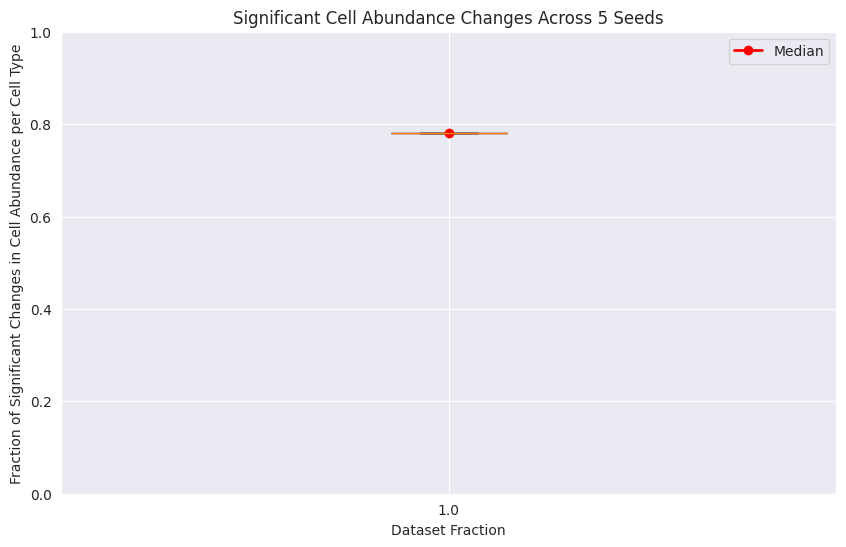

In [39]:
# Define the fractions and seeds
fractions = [1.0]
seeds = [0]

# Run the sccoda analysis
run_sccoda_analysis(whole_adata, fractions, seeds, output_dir="data")

# Collect the non-zero means
non_zero_means_dict = collect_non_zero_means(fractions, seeds, data_dir="data")

# Plot the results
plot_results(non_zero_means_dict, fractions, output_dir="figures")

Global min: -2.641339757121219, Global max: 1.2052159375872213, Symmetric range: -1.2052159375872213 to 1.2052159375872213
Clustermap saved to figures/clustermap_fraction_1_0_global_scale.png


<Figure size 640x480 with 0 Axes>

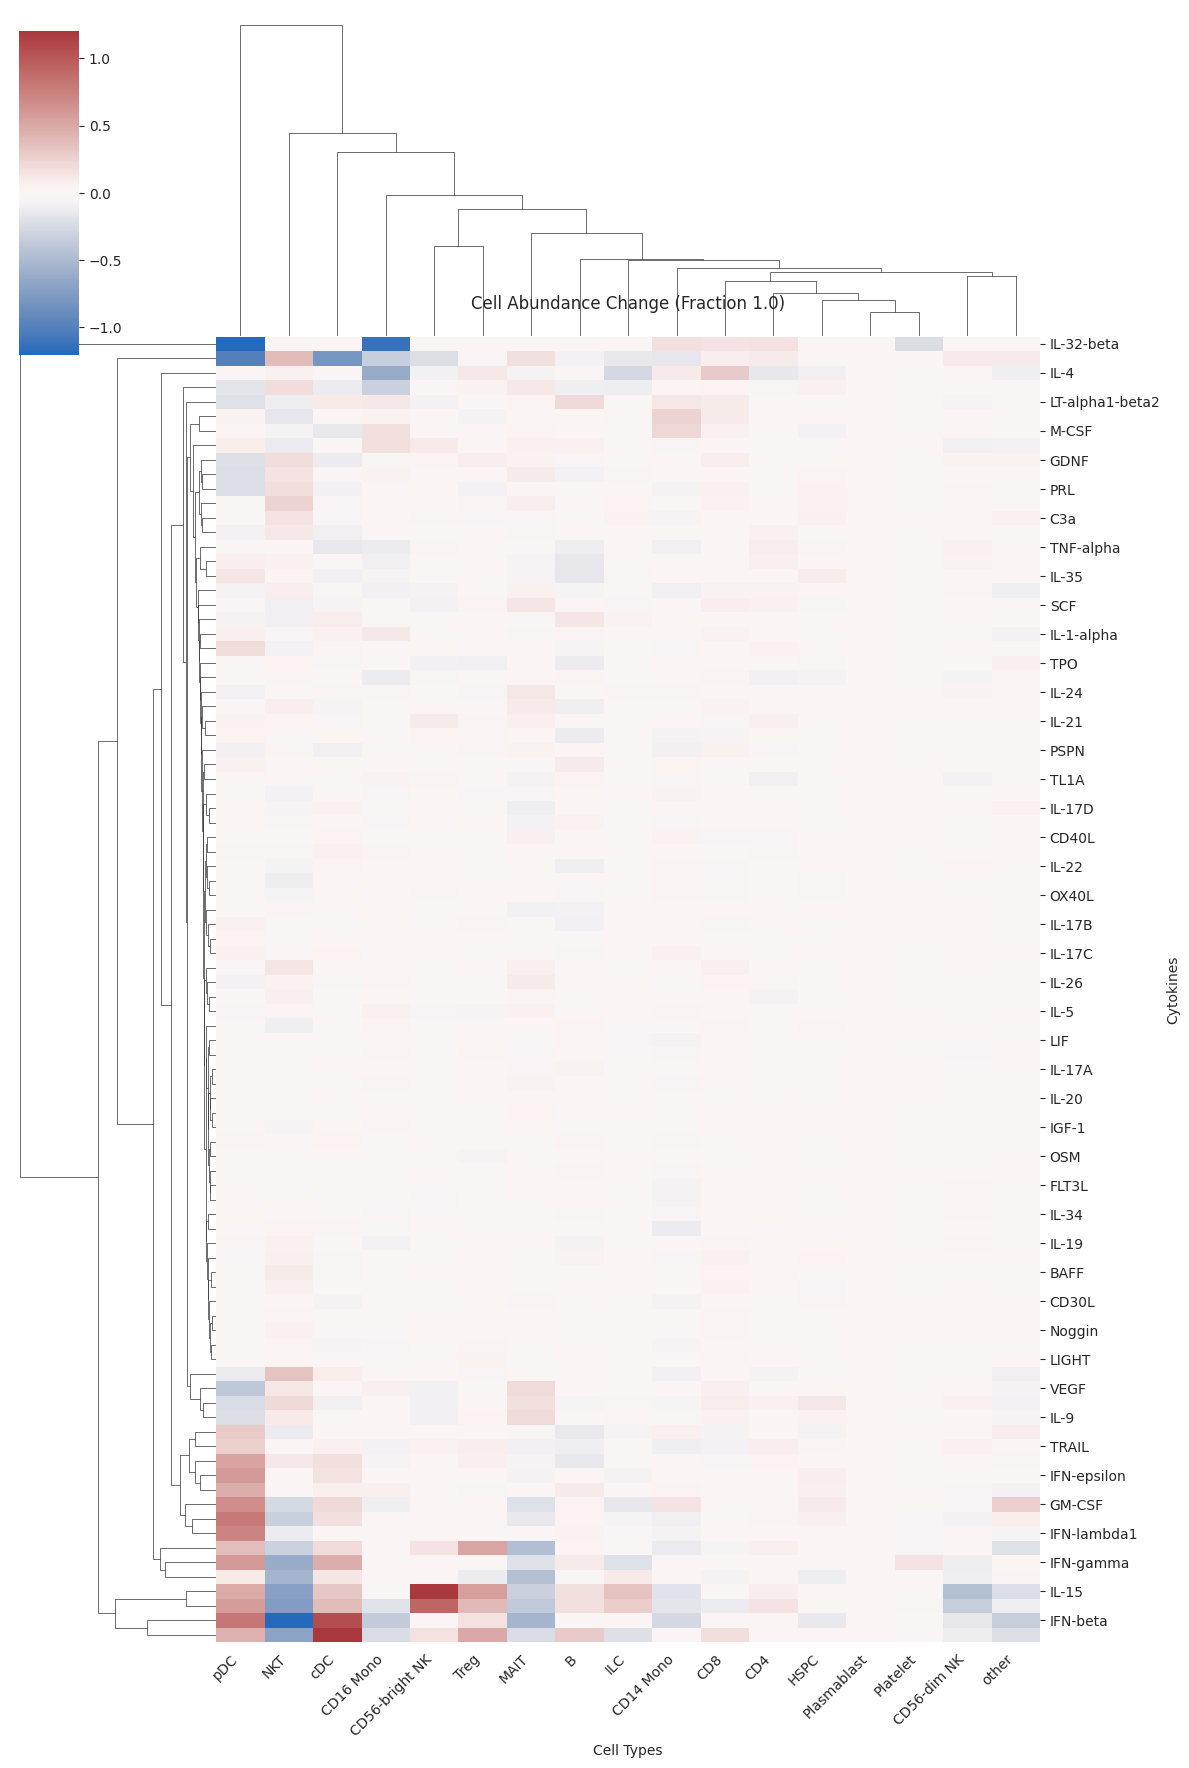

In [40]:
plot_clustermaps(output_dir="figures")